# 최종 모델 평가 (Test 1회)
**Train 내부 CV로 선정한 최종 모델 — 파생변수 36개 기반 Soft Voting(ExtraTrees + Random Forest + GBM) — 을 Train 전체(1,552건)로 다시 학습하고, Test(389건)로 평가합니다.**

- 최종 모델은 **반복 층화 CV(5×3) 평균이 가장 높은 설정**(0.8395)으로 선정했습니다(`Taegyeom_06_ensemble.ipynb`).
  5-fold 점수는 여러 설정 중 최고값을 고른 값이라 낙관적이므로, 이 노트북의 성능 비교도 **반복 CV 평균**을 기준으로 합니다.
- **선정 경위(투명성)** — 단계마다 그 시점의 최고 모델을 Test로 1회씩 평가했고, 최종 모델은 CV 결과만으로 두 번 갱신되었습니다(Test 사용 총 3회).

| 순서 | 단계별 최고 모델 | 반복 CV(5×3) | Test Macro F1 |
|---|---|---|---|
| ① | LightGBM (튜닝, 원본 26개) | 0.8260 | 0.825 |
| ② | LightGBM (파생변수 36개 + 재튜닝) | 0.8295 | 0.823 |
| ③ | **Soft Voting (ExtraTrees + RF + GBM, 36개)** | **0.8395** | 아래에서 평가 |

  갱신 판단은 매번 **CV 결과(반복 CV 평균 + fold 과반 개선)만으로 했고 Test 결과를 보고 고르지 않았습니다.** 이전 단계 모델들의 Test 결과는 비교용으로 함께 표시합니다.
- 비교를 위해 Baseline 모델과 이전 단계 모델도 같은 방식으로 Train 전체 학습 → Test 평가를 하지만, **이 결과로 최종 모델을 바꾸지 않습니다**(Test 기반 재선택은 누수).
- 희소 클래스는 Test 건수가 적어(Dirtiness 11건, Stains 14건) 클래스별 지표의 불확실성이 크므로, Macro F1의 **부트스트랩 95% 신뢰구간**을 함께 보고합니다.

In [1]:
import sys, warnings, pickle, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import joblib

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore")

from config import RANDOM_STATE
from load_data import load_data
from Taegyeom_model_utils import (CLASS_ORDER, MINORITY_CLASSES, make_pipeline, make_sampling_pipeline, build_preprocessor,
                                  discrete_indices, over_strategy, LabelEncodedClassifier, BalancedWeightClassifier,
                                  per_class_report, confusion_df, key_error_counts, add_features, PlateContextEncoder)
from Taegyeom_model_utils import FE_GROUPS
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed

RESULT_DIR = PROJECT_ROOT / "results" / "final"; RESULT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = PROJECT_ROOT / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

BLUE, BLUE_LIGHT, RED, GRAY_MID = "#2a78d6", "#86b6ef", "#e34948", "#f0efec"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
def save(fig, name): fig.savefig(FIG_DIR / name); plt.show()

## 1. 데이터와 모델 정의

In [2]:
X_train, X_test, y_train, y_test = load_data()
FEATURES = list(X_train.columns); RS = RANDOM_STATE; CAT = discrete_indices(FEATURES)
print("Train", X_train.shape, "| Test", X_test.shape)
print("Test 클래스별 건수:", y_test.value_counts().reindex(CLASS_ORDER).to_dict())

cfg = json.load(open(PROJECT_ROOT / "results/tuning/Taegyeom_tuning_best_config.json"))
LGBM_PARAMS = {k: v for k, v in cfg["params"].items() if k != "sampler"}
smotenc = lambda: SMOTENC(categorical_features=CAT, sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RS)

def final_lgbm():
    return make_sampling_pipeline(LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1, subsample_freq=1, **LGBM_PARAMS), FEATURES, smotenc())
fe_cache = pickle.load(open(PROJECT_ROOT / "results/feature_engineering/Taegyeom_fe_cache.pkl", "rb"))
FE_SEARCH = fe_cache[("retune_search", "+전체 (36개)")]
FE_BEST = FE_SEARCH.loc[FE_SEARCH["rank_test_score"].idxmin()]
X_train_fe, X_test_fe = add_features(X_train), add_features(X_test)          # 행 단위 파생변수 (형상·밝기·위치)
FE_FEATURES = list(X_train_fe.columns) + ["plate_defect_count", "thickness_per_conveyer"]   # + 강판 맥락 (Train에서만 계산)

def final_fe_lgbm():
    p = ImbPipeline([("plate", PlateContextEncoder()), ("prep", build_preprocessor(FE_FEATURES)),
                     ("sampler", SMOTENC(categorical_features=discrete_indices(FE_FEATURES), sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RS)),
                     ("model", LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1, subsample_freq=1))])
    return p.set_params(**FE_BEST["params"])

# 최종 모델: 36개 피처에서 새로 튜닝한 ExtraTrees·Random Forest·GBM의 확률 평균(Soft Voting)
v2_cache = pickle.load(open(PROJECT_ROOT / "results/ensemble/Taegyeom_ensemble_cache.pkl", "rb"))
v2_best = lambda n: (lambda r: r.loc[r["rank_test_score"].idxmin(), "params"])(v2_cache[("search", n)])
def fe_pipe(model):   # 강판 맥락 → 전처리 → (샘플러 없음) → 모델
    return ImbPipeline([("plate", PlateContextEncoder()), ("prep", build_preprocessor(FE_FEATURES)), ("sampler", "passthrough"), ("model", model)])
def v2_extratrees(): return fe_pipe(ExtraTreesClassifier(random_state=RS, n_jobs=1)).set_params(**v2_best("ExtraTrees"))
def v2_rf():         return fe_pipe(RandomForestClassifier(random_state=RS, n_jobs=1)).set_params(**v2_best("Random Forest"))
def v2_gbm():        return fe_pipe(BalancedWeightClassifier(GradientBoostingClassifier(random_state=RS), alpha=1)).set_params(**v2_best("GBM"))
def final_soft_voting():
    return VotingClassifier([("extratrees", v2_extratrees()), ("rf", v2_rf()), ("gbm", v2_gbm())], voting="soft")
for n in ["ExtraTrees", "Random Forest", "GBM"]:
    print(f"{n:14s}", {k.split("__")[-1]: v for k, v in v2_best(n).items()})

MODELS = {   # 이름: (생성 함수, 단계, 비고)
    "Logistic Regression": (lambda: make_pipeline(LogisticRegression(max_iter=5000, random_state=RS), FEATURES, scale=True), "Baseline", "불균형 처리 없음"),
    "Decision Tree":       (lambda: make_pipeline(DecisionTreeClassifier(random_state=RS), FEATURES), "Baseline", "불균형 처리 없음"),
    "Random Forest":       (lambda: make_pipeline(RandomForestClassifier(random_state=RS, n_jobs=1), FEATURES), "Baseline", "불균형 처리 없음"),
    "GBM":                 (lambda: make_pipeline(GradientBoostingClassifier(random_state=RS), FEATURES), "Baseline", "불균형 처리 없음"),
    "XGBoost":             (lambda: make_pipeline(LabelEncodedClassifier(XGBClassifier(random_state=RS, n_jobs=1)), FEATURES), "Baseline", "불균형 처리 없음"),
    "LightGBM":            (lambda: make_pipeline(LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1), FEATURES), "Baseline", "불균형 처리 없음"),
    "LightGBM (튜닝, 원본 26개)": (final_lgbm, "튜닝 단계 최고", "SMOTENC 균등화"),
    "LightGBM (파생변수 36개, 재튜닝)": (final_fe_lgbm, "파생변수 단계 최고", "SMOTENC 균등화 + class_weight=balanced"),
    "Soft Voting (ExtraTrees+RF+GBM, 36개, 최종)": (final_soft_voting, "최종 모델", "클래스 가중치 (ET balanced, GBM α=1), 샘플러 없음"),
}
FINAL = "Soft Voting (ExtraTrees+RF+GBM, 36개, 최종)"; PREV = "LightGBM (파생변수 36개, 재튜닝)"; PREV1 = "LightGBM (튜닝, 원본 26개)"
USES_FE = {FINAL, PREV}
v2_cmp = pd.read_csv(PROJECT_ROOT / "results/ensemble/Taegyeom_ensemble_candidate_comparison.csv", index_col=0)
sv_row = v2_cmp.loc["Soft Voting: ExtraTrees + Random Forest + GBM"]
short = lambda d: {k.split("__")[-1]: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items() if k != "sampler"}
final_cfg = {"model": "Soft Voting (ExtraTrees + Random Forest + GBM, 확률 평균)",
             "features": "원본 26개 + 파생변수 10개 (형상·밝기·위치·강판 맥락)",
             "imbalance": "샘플러 없음, 클래스 가중치 (ExtraTrees class_weight=balanced, GBM 균형 sample_weight α=1, RF 가중치 없음)",
             "params": {"ExtraTrees": short(v2_best("ExtraTrees")), "Random Forest": short(v2_best("Random Forest")), "GBM": short(v2_best("GBM"))},
             "cv_macro_f1_repeated_5x3": round(float(sv_row["반복 CV(5×3)"]), 4), "cv_std_repeated_5x3": round(float(sv_row["반복 CV std"]), 4),
             "cv_macro_f1_5fold": round(float(sv_row["5-fold Macro F1"]), 4),
             "selection_note": "반복 CV(5×3) 최고, 파생변수 단계 최고 LightGBM(36개) 대비 15 fold 중 11개 개선. Test를 보지 않고 CV로 선정"}
json.dump(final_cfg, open(RESULT_DIR / "Taegyeom_final_model_config.json", "w"), ensure_ascii=False, indent=2, default=str)
print("최종 모델 설정:", final_cfg)

Train (1552, 26) | Test (389, 26)
Test 클래스별 건수: {'Other_Faults': 135, 'Bumps': 81, 'K_Scratch': 78, 'Z_Scratch': 38, 'Pastry': 32, 'Stains': 14, 'Dirtiness': 11}
ExtraTrees     {'class_weight': 'balanced', 'max_depth': 15, 'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 438, 'sampler': 'passthrough'}
Random Forest  {'class_weight': None, 'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 483, 'sampler': 'passthrough'}
GBM            {'alpha': 1, 'learning_rate': np.float64(0.08793919399591556), 'max_depth': 4, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 240, 'subsample': np.float64(0.9079017872741743)}
최종 모델 설정: {'model': 'Soft Voting (ExtraTrees + Random Forest + GBM, 확률 평균)', 'features': '원본 26개 + 파생변수 10개 (형상·밝기·위치·강판 맥락)', 'imbalance': '샘플러 없음, 클래스 가중치 (ExtraTrees class_weight=balanced, GBM 균형 sample_weight α=1, RF 가중치 없음)', 'params': {'ExtraTrees': {'class_weight': 'balanced', 'max_depth': 15, 'max_features': 0.7, 'min_sample

## 2. Train 전체 학습 → Test 1회 평가

In [3]:
def fit_eval(name):
    make, stage, note = MODELS[name]
    Xtr, Xte = (X_train_fe, X_test_fe) if name in USES_FE else (X_train, X_test)
    m = make(); t0 = time.perf_counter(); m.fit(Xtr, y_train); sec = time.perf_counter() - t0
    pred = m.predict(Xte); proba = m.predict_proba(Xte)
    return name, m, pred, proba, sec

t0 = time.perf_counter()
outs = Parallel(n_jobs=-1)(delayed(fit_eval)(n) for n in MODELS)
print(f"소요 {time.perf_counter() - t0:.0f}초")
fitted = {n: dict(model=m, pred=p, proba=pr, sec=s) for n, m, p, pr, s in outs}

# CV 참고값: 5-fold 평균(각 단계 노트북) + 반복 CV(5×3) 평균(비교 판단 기준, 계산한 모델만)
cv_ref = {}
base_cv = pd.read_csv(PROJECT_ROOT / "results/baseline/Taegyeom_baseline_cv_summary.csv", index_col=0)
for n in base_cv.index: cv_ref[n] = base_cv.loc[n, "macro_f1_mean"]
tsel = pd.read_csv(PROJECT_ROOT / "results/tuning/Taegyeom_tuning_final_selection.csv", index_col=0)
cv_ref[PREV1] = cfg["cv_macro_f1_5fold"]
cv_ref[PREV] = float(FE_BEST["mean_test_score"]); cv_ref[FINAL] = final_cfg["cv_macro_f1_5fold"]
rep_ref = {PREV1: 0.8260, PREV: 0.8295, FINAL: final_cfg["cv_macro_f1_repeated_5x3"]}

rows = []
for n, r in fitted.items():
    p = r["pred"]; classes = list(r["model"].classes_)
    rows.append({"모델": n, "단계": MODELS[n][1], "불균형 처리": MODELS[n][2],
                 "반복 CV(5×3)": rep_ref.get(n, np.nan), "5-fold CV": cv_ref[n],
                 "Test Macro F1": f1_score(y_test, p, average="macro"), "Test Accuracy": accuracy_score(y_test, p),
                 "Test Macro Precision": precision_score(y_test, p, average="macro"), "Test Macro Recall": recall_score(y_test, p, average="macro"),
                 "Test Weighted F1": f1_score(y_test, p, average="weighted"),
                 "Test Macro ROC-AUC": roc_auc_score(y_test, r["proba"], multi_class="ovr", labels=classes),
                 "학습 시간(초)": r["sec"]})
test_tbl = pd.DataFrame(rows).set_index("모델")
test_tbl.to_csv(RESULT_DIR / "Taegyeom_final_test_comparison.csv")
test_tbl.round(4)

소요 28초


,단계,불균형 처리,반복 CV(5×3),5-fold CV,Test Macro F1,Test Accuracy,Test Macro Precision,Test Macro Recall,Test Weighted F1,Test Macro ROC-AUC,학습 시간(초)
모델,,,,,,,,,,,
Logistic Regression,Baseline,불균형 처리 없음,NaN,0.7191,0.7387,0.7249,0.7595,0.7261,0.7245,0.9384,0.1103
Decision Tree,Baseline,불균형 처리 없음,NaN,0.7207,0.7411,0.7404,0.7436,0.7453,0.7389,0.8479,0.0615
Random Forest,Baseline,불균형 처리 없음,NaN,0.7899,0.7861,0.7763,0.8384,0.7500,0.7753,0.9625,0.4986
GBM,Baseline,불균형 처리 없음,NaN,0.7963,0.8068,0.7918,0.8527,0.7756,0.7937,0.9621,5.1283
XGBoost,Baseline,불균형 처리 없음,NaN,0.8109,0.8165,0.8072,0.8272,0.8072,0.8090,0.9648,1.0348
LightGBM,Baseline,불균형 처리 없음,NaN,0.8044,0.8371,0.8226,0.8585,0.8205,0.8234,0.9671,1.0823
"LightGBM (튜닝, 원본 26개)",튜닝 단계 최고,SMOTENC 균등화,0.8260,0.8298,0.8252,0.8098,0.8254,0.8259,0.8110,0.9705,6.6607
"LightGBM (파생변수 36개, 재튜닝)",파생변수 단계 최고,SMOTENC 균등화 + class_weight=balanced,0.8295,0.8317,0.8226,0.8046,0.8137,0.8336,0.8049,0.9702,2.6960
"Soft Voting (ExtraTrees+RF+GBM, 36개, 최종)",최종 모델,"클래스 가중치 (ET balanced, GBM α=1), 샘플러 없음",0.8395,0.8430,0.8279,0.8046,0.8447,0.8128,0.8065,0.9687,17.1861


In [4]:
# 최종 모델 Test Macro F1의 부트스트랩 95% 신뢰구간 (Test 389건 복원추출 2,000회)
rng = np.random.default_rng(RS); yt = y_test.values; yp = fitted[FINAL]["pred"]
boot = np.array([f1_score(yt[i], yp[i], average="macro") for i in (rng.integers(0, len(yt), len(yt)) for _ in range(2000))])
ci = np.percentile(boot, [2.5, 97.5])
final_f1 = f1_score(yt, yp, average="macro")
print(f"최종 모델 Test Macro F1 = {final_f1:.4f}  (95% CI {ci[0]:.4f} ~ {ci[1]:.4f}),  목표 0.83 이상일 확률(부트스트랩) {np.mean(boot >= 0.83):.0%}")
json.dump({"test_macro_f1": round(final_f1, 4), "ci95": [round(ci[0], 4), round(ci[1], 4)], "p_ge_0.83": round(float(np.mean(boot >= 0.83)), 3)},
          open(RESULT_DIR / "Taegyeom_final_test_ci.json", "w"), indent=2)
joblib.dump(fitted[FINAL]["model"], MODEL_DIR / "Taegyeom_final_model.pkl", compress=3)   # 입력: add_features(X) 적용 데이터 (34열 → 파이프라인 안에서 36개)
print("최종 모델 저장:", (MODEL_DIR / "Taegyeom_final_model.pkl").relative_to(PROJECT_ROOT))

최종 모델 Test Macro F1 = 0.8279  (95% CI 0.7851 ~ 0.8647),  목표 0.83 이상일 확률(부트스트랩) 45%


최종 모델 저장: models/Taegyeom_final_model.pkl


## 3. 최종 모델 상세 — 클래스별 지표와 혼동행렬

In [5]:
fin = fitted[FINAL]["pred"]; base = fitted["XGBoost"]["pred"]; prev = fitted[PREV]["pred"]
rep = pd.concat({"최고 Baseline (XGBoost)": per_class_report(y_test, base), "파생변수 단계 최고 (LightGBM 36개)": per_class_report(y_test, prev), "최종 모델": per_class_report(y_test, fin)}, axis=1).round(3)
rep.to_csv(RESULT_DIR / "Taegyeom_final_test_per_class.csv")
display(rep)
ke = pd.DataFrame({"최고 Baseline (XGBoost)": key_error_counts(y_test, base), "파생변수 단계 최고 (LightGBM 36개)": key_error_counts(y_test, prev), "최종 모델": key_error_counts(y_test, fin)})
ke["변화 (Baseline 대비)"] = ke["최종 모델"] - ke.iloc[:, 0]; ke.to_csv(RESULT_DIR / "Taegyeom_final_test_key_errors.csv")
ke

최고 Baseline (XGBoost)                       파생변수 단계 최고 (LightGBM 36개)                           최종 모델                      
                         precision recall     f1 support                 precision recall     f1 support precision recall     f1 support
Other_Faults                 0.747  0.807  0.776     135                     0.759  0.770  0.765     135     0.738  0.793  0.764     135
Bumps                        0.740  0.704  0.722      81                     0.714  0.679  0.696      81     0.734  0.716  0.725      81
K_Scratch                    0.986  0.923  0.954      78                     0.987  0.962  0.974      78     0.986  0.936  0.961      78
Z_Scratch                    1.000  0.947  0.973      38                     0.974  0.974  0.974      38     1.000  0.947  0.973      38
Pastry                       0.576  0.594  0.585      32                     0.559  0.594  0.576      32     0.531  0.531  0.531      32
Stains                       0.923  0.857  0.889      14                     0.857  0.857  0.857      14     0.923  0.857  0.889      14
Dirtiness                    0.818  0.818  0.818      11                     0.846  1.000  0.917      11     1.000  0.909  0.952      11

,최고 Baseline (XGBoost),파생변수 단계 최고 (LightGBM 36개),최종 모델,변화 (Baseline 대비)
소수 유형 → Other_Faults·Bumps,17,14,18,1
Other_Faults → 소수 유형 (오경보),10,12,11,1
Bumps ↔ Other_Faults,33,38,35,2
K_Scratch ↔ Z_Scratch,0,0,0,0
전체 오분류,75,76,76,1


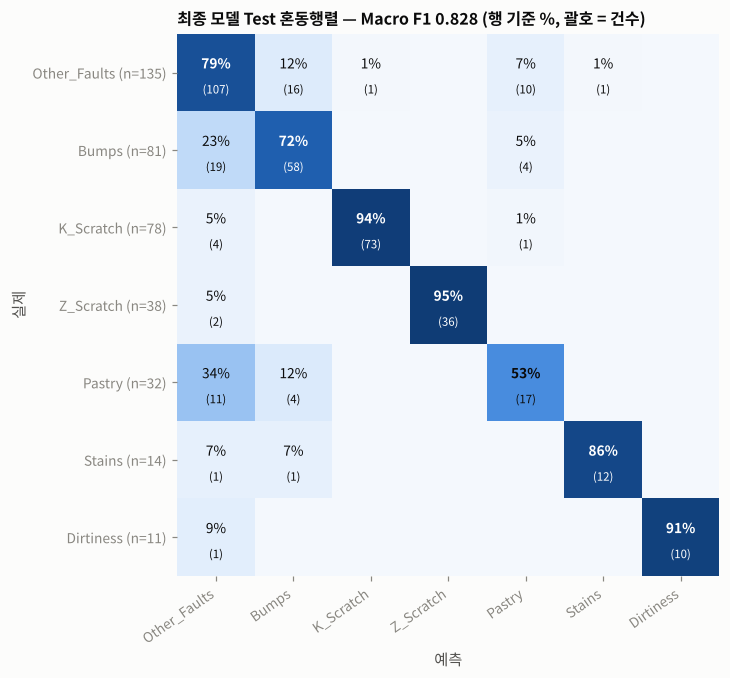

In [6]:
cm = confusion_df(y_test, fin); pct = cm.div(cm.sum(axis=1), axis=0) * 100
cm.to_csv(RESULT_DIR / "Taegyeom_final_test_confusion.csv")
fig, ax = plt.subplots(figsize=(7.4, 6.4))
ax.imshow(pct.values, cmap=SEQ, vmin=0, vmax=100)
for i in range(7):
    for j in range(7):
        if cm.values[i, j]:
            col = "white" if pct.values[i, j] > 55 else INK
            ax.text(j, i - 0.12, f"{pct.values[i, j]:.0f}%", ha="center", va="center", fontsize=9, color=col, fontweight="bold" if i == j else None)
            ax.text(j, i + 0.22, f"({cm.values[i, j]})", ha="center", va="center", fontsize=7.5, color=col)
ax.set_xticks(range(7), CLASS_ORDER, rotation=35, ha="right", fontsize=9); ax.set_yticks(range(7), [f"{c} (n={n})" for c, n in zip(CLASS_ORDER, cm.sum(axis=1))], fontsize=9)
ax.set_xlabel("예측"); ax.set_ylabel("실제"); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title(f"최종 모델 Test 혼동행렬 — Macro F1 {final_f1:.3f} (행 기준 %, 괄호 = 건수)", fontsize=10.5)
save(fig, "Taegyeom_final_test_confusion.png")

## 4. 대표 오분류 사례

In [7]:
proba = pd.DataFrame(fitted[FINAL]["proba"], columns=fitted[FINAL]["model"].classes_, index=X_test.index)
plate = lambda X: X[["Length_of_Conveyer", "Steel_Plate_Thickness", "TypeOfSteel_A300"]].astype(str).agg("_".join, axis=1)
seen = plate(X_test).isin(set(plate(X_train)))
err = pd.DataFrame({"실제": y_test, "예측": fin, "예측 확률": proba.max(axis=1).round(3),
                    "실제 클래스 확률": [round(proba.loc[i, c], 3) for i, c in zip(X_test.index, y_test)],
                    "Train에 같은 강판 조건 존재": seen,
                    "LogOfAreas": X_test["LogOfAreas"].round(2), "Steel_Plate_Thickness": X_test["Steel_Plate_Thickness"],
                    "Length_of_Conveyer": X_test["Length_of_Conveyer"], "Minimum_of_Luminosity": X_test["Minimum_of_Luminosity"],
                    "Orientation_Index": X_test["Orientation_Index"].round(2)})
wrong = err[err["실제"] != err["예측"]].copy()
wrong["오분류 경로"] = wrong["실제"] + " → " + wrong["예측"]
print(f"Test 오분류 {len(wrong)}건 / 389건")
print("오분류 경로별 건수 (상위)"); display(wrong["오분류 경로"].value_counts().head(10))
print("Train에 없던 강판 조건의 결함:", (~seen).sum(), "건 → 그중 오분류", (~seen & (err["실제"] != err["예측"])).sum(), "건")
wrong.sort_values("예측 확률", ascending=False).to_csv(RESULT_DIR / "Taegyeom_final_test_errors.csv")
# 경로별 대표 사례: 확신하고 틀린 경우(예측 확률 최대)
cases = (wrong.sort_values("예측 확률", ascending=False).groupby("오분류 경로").head(1)
         .loc[lambda d: d["오분류 경로"].isin(wrong["오분류 경로"].value_counts().head(6).index)])
cases.to_csv(RESULT_DIR / "Taegyeom_final_test_error_cases.csv")
cases

Test 오분류 76건 / 389건
오분류 경로별 건수 (상위)


오분류 경로
Bumps → Other_Faults        19
Other_Faults → Bumps        16
Pastry → Other_Faults       11
Other_Faults → Pastry       10
Pastry → Bumps               4
Bumps → Pastry               4
K_Scratch → Other_Faults     4
Z_Scratch → Other_Faults     2
Dirtiness → Other_Faults     1
Other_Faults → Stains        1
Name: count, dtype: int64

Train에 없던 강판 조건의 결함: 24 건 → 그중 오분류 8 건


,실제,예측,예측 확률,실제 클래스 확률,Train에 같은 강판 조건 존재,LogOfAreas,Steel_Plate_Thickness,Length_of_Conveyer,Minimum_of_Luminosity,Orientation_Index,오분류 경로
1035,Bumps,Other_Faults,0.923,0.040,False,1.71,211,1686,77,-0.75,Bumps → Other_Faults
1661,Other_Faults,Bumps,0.887,0.110,True,2.01,80,1694,85,-0.08,Other_Faults → Bumps
144,Pastry,Bumps,0.817,0.022,True,2.02,40,1362,84,0.29,Pastry → Bumps
1181,Bumps,Pastry,0.771,0.128,True,2.28,70,1688,82,0.72,Bumps → Pastry
1273,Other_Faults,Pastry,0.751,0.118,True,2.43,70,1353,71,0.59,Other_Faults → Pastry
124,Pastry,Other_Faults,0.726,0.197,False,2.13,90,1694,94,0.70,Pastry → Other_Faults


## 5. 최종 모델 피처 중요도 (Permutation, Test)

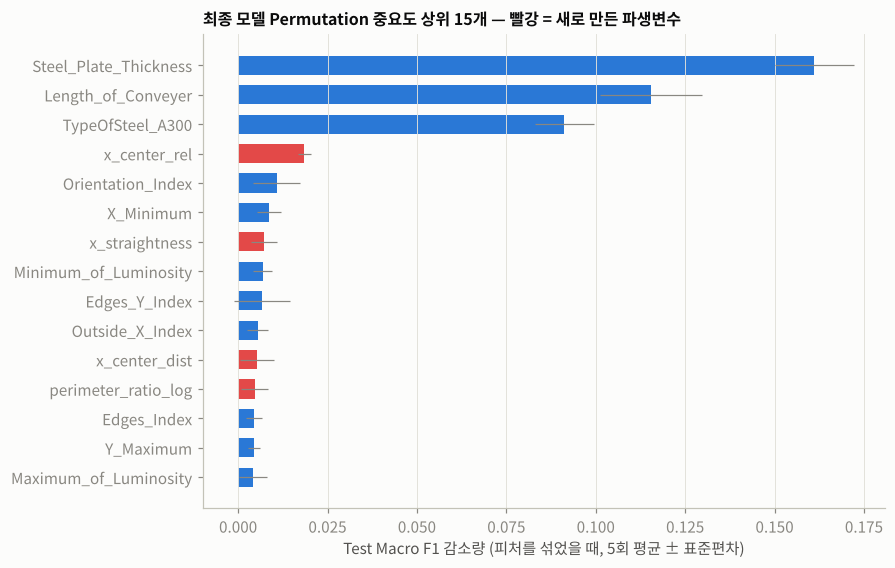

,perm_drop_mean,perm_drop_std,파생변수
Steel_Plate_Thickness,0.1611,0.0111,False
Length_of_Conveyer,0.1154,0.0143,False
TypeOfSteel_A300,0.0913,0.0082,False
x_center_rel,0.0185,0.0018,True
Orientation_Index,0.0108,0.0065,False
X_Minimum,0.0087,0.0034,False
x_straightness,0.0073,0.0037,True
Minimum_of_Luminosity,0.0069,0.0026,False
Edges_Y_Index,0.0067,0.0079,False
Outside_X_Index,0.0055,0.0029,False


In [8]:
from sklearn.inspection import permutation_importance
fm = fitted[FINAL]["model"]
pi = permutation_importance(fm, X_test_fe, y_test, scoring="f1_macro", n_repeats=5, random_state=RS, n_jobs=-1)
imp = pd.DataFrame({"perm_drop_mean": pi.importances_mean, "perm_drop_std": pi.importances_std}, index=X_test_fe.columns).sort_values("perm_drop_mean", ascending=False)
imp["파생변수"] = [c not in FEATURES for c in imp.index]
imp.to_csv(RESULT_DIR / "Taegyeom_final_feature_importance.csv")
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(top.index, top["perm_drop_mean"], xerr=top["perm_drop_std"], color=[RED if d else BLUE for d in top["파생변수"]], height=0.65,
        error_kw=dict(ecolor=MUTED, lw=0.8, capsize=0))
ax.grid(axis="y", visible=False); ax.set_xlabel("Test Macro F1 감소량 (피처를 섞었을 때, 5회 평균 ± 표준편차)")
ax.set_title("최종 모델 Permutation 중요도 상위 15개 — 빨강 = 새로 만든 파생변수", fontsize=10.5)
save(fig, "Taegyeom_final_feature_importance.png")
imp.head(15).round(4)

## 6. 결과 해석
> 모델 간 비교는 **반복 층화 CV(5×3) 평균**을 기준으로 하고, Test는 389건 1회 분할이라 참고 확인용으로만 봅니다.

- **최종 모델(Soft Voting: ExtraTrees + RF + GBM, 36개)의 반복 CV 평균은 0.8395**로 후보 중 가장 높고, 반복 CV 평균 기준으로 **목표 0.83을 넘은 유일한 모델**입니다(파생변수 단계 최고 LightGBM 36개 0.8295, 튜닝 단계 최고 LightGBM 26개 0.8260).
- **Test Macro F1 = 0.828** (95% 신뢰구간 0.785 ~ 0.865, Accuracy 0.805). 반복 CV 추정(0.8395)보다 약 0.012 낮지만 신뢰구간 안이며, **목표 0.83에는 0.002 못 미칩니다**(부트스트랩 기준 0.83 이상일 확률 약 45%).
  이전 단계 모델들(Test 0.825, 0.823)보다 소폭 높지만 그 차이(+0.003~0.005)는 Test 변동 범위(신뢰구간 폭 약 ±0.04) 안이므로, **우위의 근거는 Test가 아니라 반복 CV(15 fold 중 11개 개선)** 입니다.
- Baseline LightGBM의 Test 점수(0.837)가 더 높게 나왔지만 5-fold CV는 0.804 ± 0.036으로 낮고 편차가 커서 단일 Test 분할의 우연으로 판단하며, Test 결과로 최종 모델을 바꾸지 않습니다.
- **클래스별 (최고 Baseline XGBoost 대비)**: Dirtiness F1 0.818 → 0.952, K_Scratch 0.954 → 0.961로 개선, Z_Scratch(0.973)·Stains(0.889)·Bumps(0.722 → 0.725)·Other_Faults(0.776 → 0.764)는 비슷합니다.
  **Pastry는 0.585 → 0.531로 오히려 낮아져 가장 약한 유형**으로 남았습니다(Test 32건 중 17건 정답).
- 확률 평균 모델은 Precision(0.845)이 높고 Recall(0.813)이 상대적으로 낮습니다. SMOTENC를 쓰던 LightGBM(36개)보다 소수 유형 오경보는 비슷하지만(12 → 11건) **소수 유형 놓침이 14 → 18건으로 늘었습니다** — 샘플러 없이 클래스 가중치만 쓰는 구성이라 소수 유형을 덜 공격적으로 예측합니다.
- **최대 오류원은 여전히 Bumps ↔ Other_Faults(35건, 전체 오분류 76건의 46%)**, 다음은 Other_Faults ↔ Pastry(21건)입니다.
- **처음 보는 강판 조건의 결함은 오분류율이 높습니다**: Train에 없던 (컨베이어 길이·두께·강종) 조건의 Test 결함 24건 중 8건(33%)이 오분류되어 전체 오분류율(20%)보다 높습니다.
- **피처 중요도**: 강판 두께(0.161)·컨베이어 길이(0.115)·강종(0.091)이 압도적 상위이며, 새 파생변수 중 `x_center_rel`이 4위(0.019)이고 `x_straightness`·`x_center_dist`·`perimeter_ratio_log`도 상위 15위 안에 들었습니다.
  강판 맥락 파생변수(`plate_defect_count`, `thickness_per_conveyer`)는 파이프라인 안에서 두께·컨베이어 길이로부터 계산되므로 그 효과는 두 원본 변수의 중요도에 함께 반영됩니다.
- **운영 비용**: 세 모델을 모두 학습해야 해 학습 시간이 약 18초(LightGBM 단일 약 3초)로 늘지만, 배치 예측 용도에는 문제가 없는 수준입니다.